In [1]:
Megavardhini.S 
II-MCA

In [28]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import MobileNetV2

In [29]:
train_path = r"D:\program\Train"
test_path  = r"D:\program\Test"

In [30]:
IMG_SIZE =(224,224)
BATCH_SIZE=32
SEED =42

In [31]:
train_dataset = image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="training",
    seed=SEED
)

validation_dataset = image_dataset_from_directory(
    train_path, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    validation_split=0.20, subset="validation", seed=SEED
)

test_dataset = image_dataset_from_directory(
    test_path, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False
)

Found 1322 files belonging to 1 classes.
Using 1058 files for training.
Found 1322 files belonging to 1 classes.
Using 264 files for validation.
Found 150 files belonging to 1 classes.


In [32]:
class_names = train_dataset.class_names
print("Number of classes:", len(class_names))
print("\nDisease classes")
for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 1

Disease classes
0 : Train


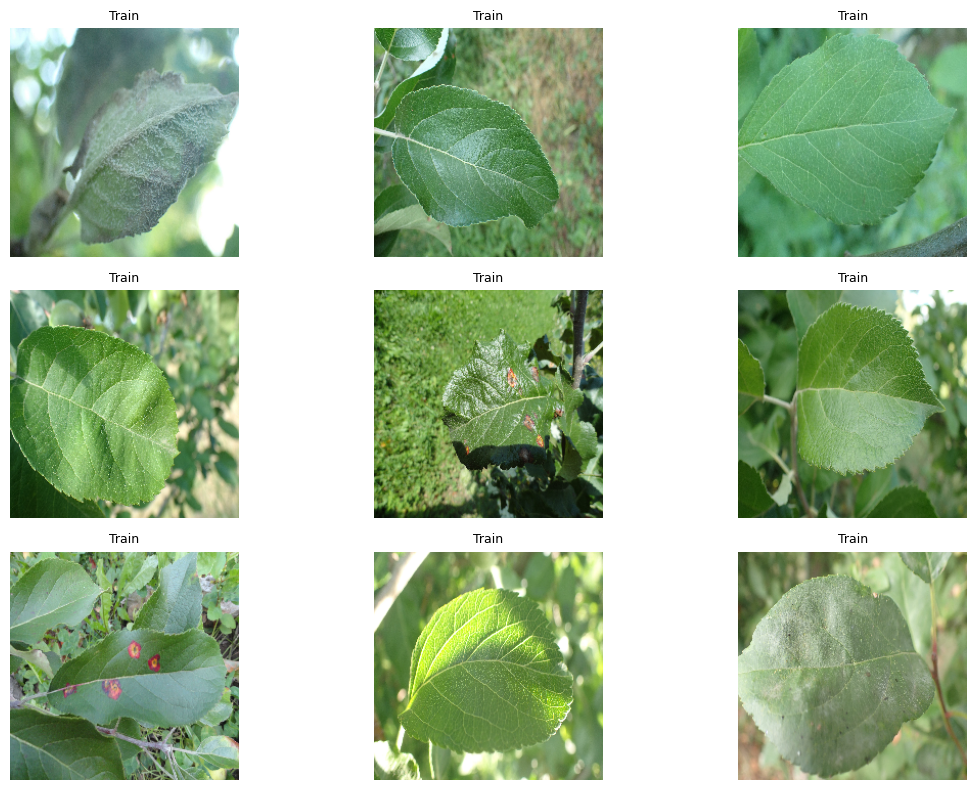

In [27]:
# Sample images from the training set
plt.figure(figsize=(12, 8))
for images, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [9]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

In [10]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),   # same as MobileNetV2 preprocess_input
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 2,225,153 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=callbacks 
)

Epoch 1/10


C:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\ops\nn.py:946: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


34/34 ━━━━━━━━━━━━━━━━━━━━ 294s 7s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 259s 8s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 251s 7s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 270s 8s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 5.0000e-04


In [13]:
base_model.trainable = True
for layer in base_model.layers[:-30]:      # keep everything except the last 30 layers frozen
    layer.trainable = False

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # very low LR for fine-tuning
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 70s 2s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 3/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 5.0000e-06


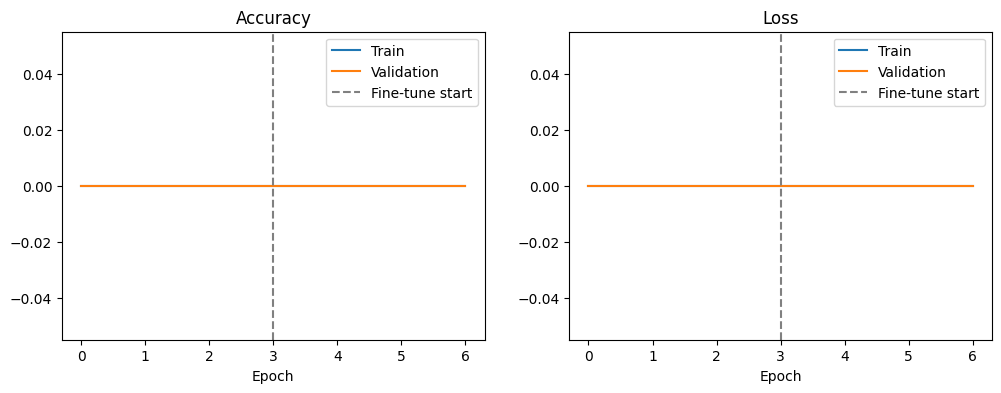

In [15]:
# Training curves (both phases combined)
acc     = history.history["accuracy"]     + history_fine.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_fine.history["val_accuracy"]
loss     = history.history["loss"]     + history_fine.history["loss"]
val_loss = history.history["val_loss"] + history_fine.history["val_loss"]
split = len(history.history["accuracy"]) - 1

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label="Train"); plt.plot(val_acc, label="Validation")
plt.axvline(split, color="gray", linestyle="--", label="Fine-tune start")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Train"); plt.plot(val_loss, label="Validation")
plt.axvline(split, color="gray", linestyle="--", label="Fine-tune start")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

In [16]:
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00
Test accuracy: 0.0000


C:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\ops\nn.py:946: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


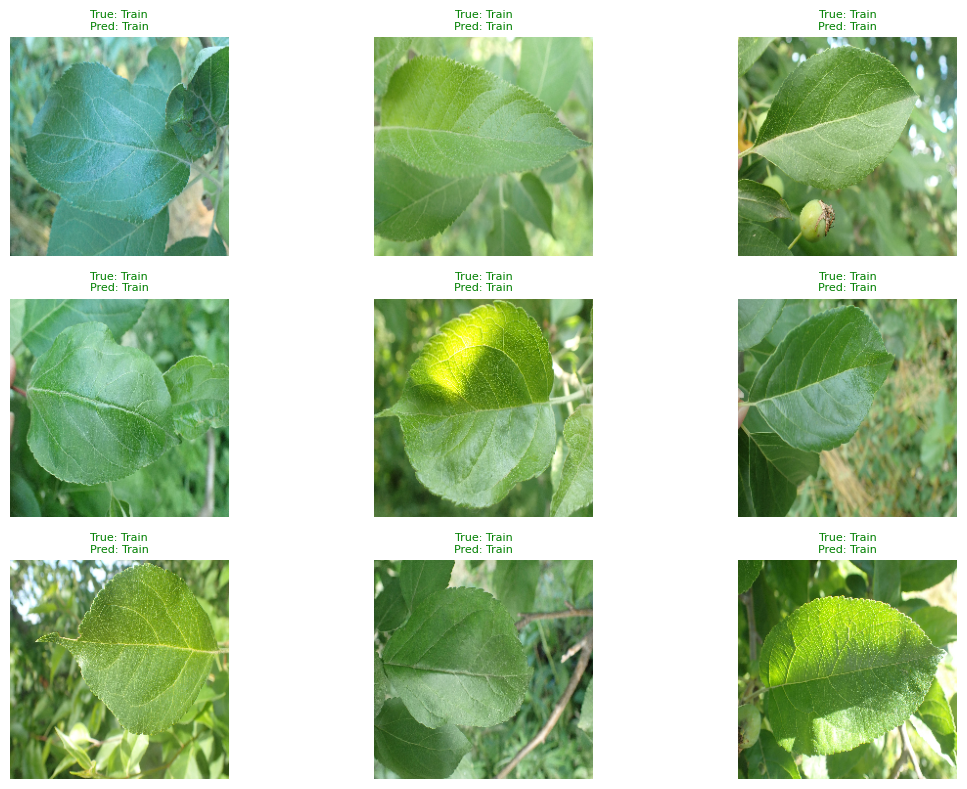

In [17]:
# Predictions on a few test images
plt.figure(figsize=(12, 8))
for images, labels in test_dataset.take(1):
    preds = np.argmax(model.predict(images), axis=1)
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        color = "green" if preds[i] == labels[i] else "red"
        plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[preds[i]]}", color=color, fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()

In [18]:
model.save("mobilenet_leaf_disease.keras")